# rd_fuzzy_pmgsy

> 对应代码：`EconometricsCode/code_in_notes/Chap.20/rd_fuzzy_pmgsy.do`（本 notebook 中的 Stata 代码与 do 文件一致）
>
> 运行方式：通过 *PyStata* 在 Jupyter 中调用 Stata，安装与使用说明见 `notebooks/PyStata.md`。

**说明**：本 notebook 的 Stata 代码与 `.do` 文件完全一致（这两个 do 文件中没有 `graph export` 命令），散点与拟合曲线、`rdplot` 图以及密度图都由 PyStata 在 notebook 中直接内联显示。

首先启动 Stata 环境，并把工作目录切换到 `code_in_notes/Chap.20`，这样 Stata 中的相对路径（如 `../datasets/...`）与同名 do 文件完全一致，图片也会输出到该目录。

In [1]:
# 配置 PyStata：启动 Stata 并注册 %%stata 魔法命令
import os
os.chdir("../../code_in_notes/Chap.20")

import stata_setup
stata_setup.config("/opt/Stata", "mp")


  ___  ____  ____  ____  ____ ®
 /__    /   ____/   /   ____/      Stata 18.0
___/   /   /___/   /   /___/       MP—Parallel Edition

 Statistics and Data Science       Copyright 1985-2023 StataCorp LLC
                                   StataCorp
                                   4905 Lakeway Drive
                                   College Station, Texas 77845 USA
                                   800-782-8272        https://www.stata.com
                                   979-696-4600        service@stata.com

Stata license: Single-user 16-core  perpetual
Serial number: 501806307019
  Licensed to: Keep calm and DO your research
               Jichun Si

Notes:
      1. Unicode is supported; see help unicode_advice.
      2. More than 2 billion observations are allowed; see help obs_advice.
      3. Maximum number of variables is set to 5,000 but can be increased;
          see help set_maxvar.


这一节使用 Asher and Novosad (2020) 研究印度农村道路项目（PMGSY）的数据。项目按村庄人口规模排序，人口超过门槛的村庄优先获得修路资格，因此人口相对门槛的偏离 `v_pop` 是运行变量、`v_pop = 0` 是断点。`t` 表示是否达到人口门槛（获得修路优先资格），`r2012` 表示到 2012 年村庄是否实际修通了公路，结果变量 `transport_index_andrsn` 是交通可达性的 Andersen 指数。

In [2]:
%%stata
// rd_fuzzy_pmgsy.do
clear
set more off
use ../datasets/pmgsy_working_aer_mainsample.dta, clear


. // rd_fuzzy_pmgsy.do
. clear

. set more off

. use ../datasets/pmgsy_working_aer_mainsample.dta, clear
(PC + EC rural + urban panel)

. 


这是一个**模糊断点**（**fuzzy RD**）设计：达到人口门槛只是提高了修路的概率，并不保证一定修路，所以 `t` 与 `r2012` 并不相同。我们先按**三角核**（**triangular kernel**）构造权重：`kw = max(bw - |v_pop|, 0)`，在断点处权重最大、向两侧线性递减，超出窗宽 `bw = 80` 的观测权重为 0。把它作为分析权重放进回归，就等价于做核加权的局部线性估计。

In [3]:
%%stata
// triangle kernel and bandwidth
local bw = 80
gen kw = max(`bw'-abs(v_pop),0)


. // triangle kernel and bandwidth
. local bw = 80

. gen kw = max(`bw'-abs(v_pop),0)

. 


与前面的做法一样，我们构造断点两侧各自的多项式项：`l1`、`r1` 是一次项，`l2`、`r2` 是二次项。以 `l1` 为例，它在 `v_pop<0` 时等于 `|v_pop|`、在右侧等于 0，因此左右两侧可以有不同斜率，而 `t`（或后面的 `r2012`）的系数就是断点处的跳跃。

In [4]:
%%stata
// polynomials left and right
gen l1 = abs(v_pop) if v_pop<0
replace l1 = 0 if v_pop>=0
gen r1 = abs(v_pop) if v_pop>=0
replace r1 =0 if v_pop<0
gen l2 = l1^2
gen r2 = r1^2


. // polynomials left and right
. gen l1 = abs(v_pop) if v_pop<0
(5,414 missing values generated)

. replace l1 = 0 if v_pop>=0
(5,414 real changes made)

. gen r1 = abs(v_pop) if v_pop>=0
(6,018 missing values generated)

. replace r1 =0 if v_pop<0
(6,018 real changes made)

. gen l2 = l1^2

. gen r2 = r1^2

. 


控制变量 `controls` 是村庄层面的社会经济特征（基础教育、医疗、通电、土地、识字率等），`fe` 是区县固定效应 `vhg_dist_id`，`clse` 指定聚类层级 `dist_id`。把这些名称放进局部宏，后面各条回归命令重复使用，可以避免写错变量名。

In [5]:
%%stata
// control variables
local controls  primary_school med_center elect tdist irr_share ln_land pc01_lit_share pc01_sc_share bpl_landed_share bpl_inc_source_sub_share bpl_inc_250plus
local fe vhg_dist_id
local clse dist_id


. // control variables
. local controls  primary_school med_center elect tdist irr_share ln_land pc01_
> lit_share pc01_sc_share bpl_landed_share bpl_inc_source_sub_share bpl_inc_250
> plus

. local fe vhg_dist_id

. local clse dist_id

. 


第一步仍然要做操纵检验：如果村庄能够通过虚报人口跨过门槛，断点附近的样本就不是可比的。`rddensity` 检验 `v_pop` 在 0 处的密度是否连续，`hist_n(10)` 指定直方图的分箱方式。


. // manipulation test
. rddensity v_pop, plot hist_n(10)
Computing data-driven bandwidth selectors.

Point estimates and standard errors have been adjusted for repeated observation
> s.
(Use option nomasspoints to suppress this adjustment.)

RD Manipulation test using local polynomial density estimation.

     c =     0.000 | Left of c  Right of c          Number of obs =        1143
> 2
-------------------+----------------------          Model         = unrestricte
> d
     Number of obs |      6018        5414          BW method     =         com
> b
Eff. Number of obs |      2952        2969          Kernel        =   triangula
> r
    Order est. (p) |         2           2          VCE method    =    jackknif
> e
    Order bias (q) |         3           3
       BW est. (h) |    41.045      43.628

Running variable: v_pop.
------------------------------------------
            Method |      T          P>|T|
-------------------+----------------------
            Robust |   -0.6425

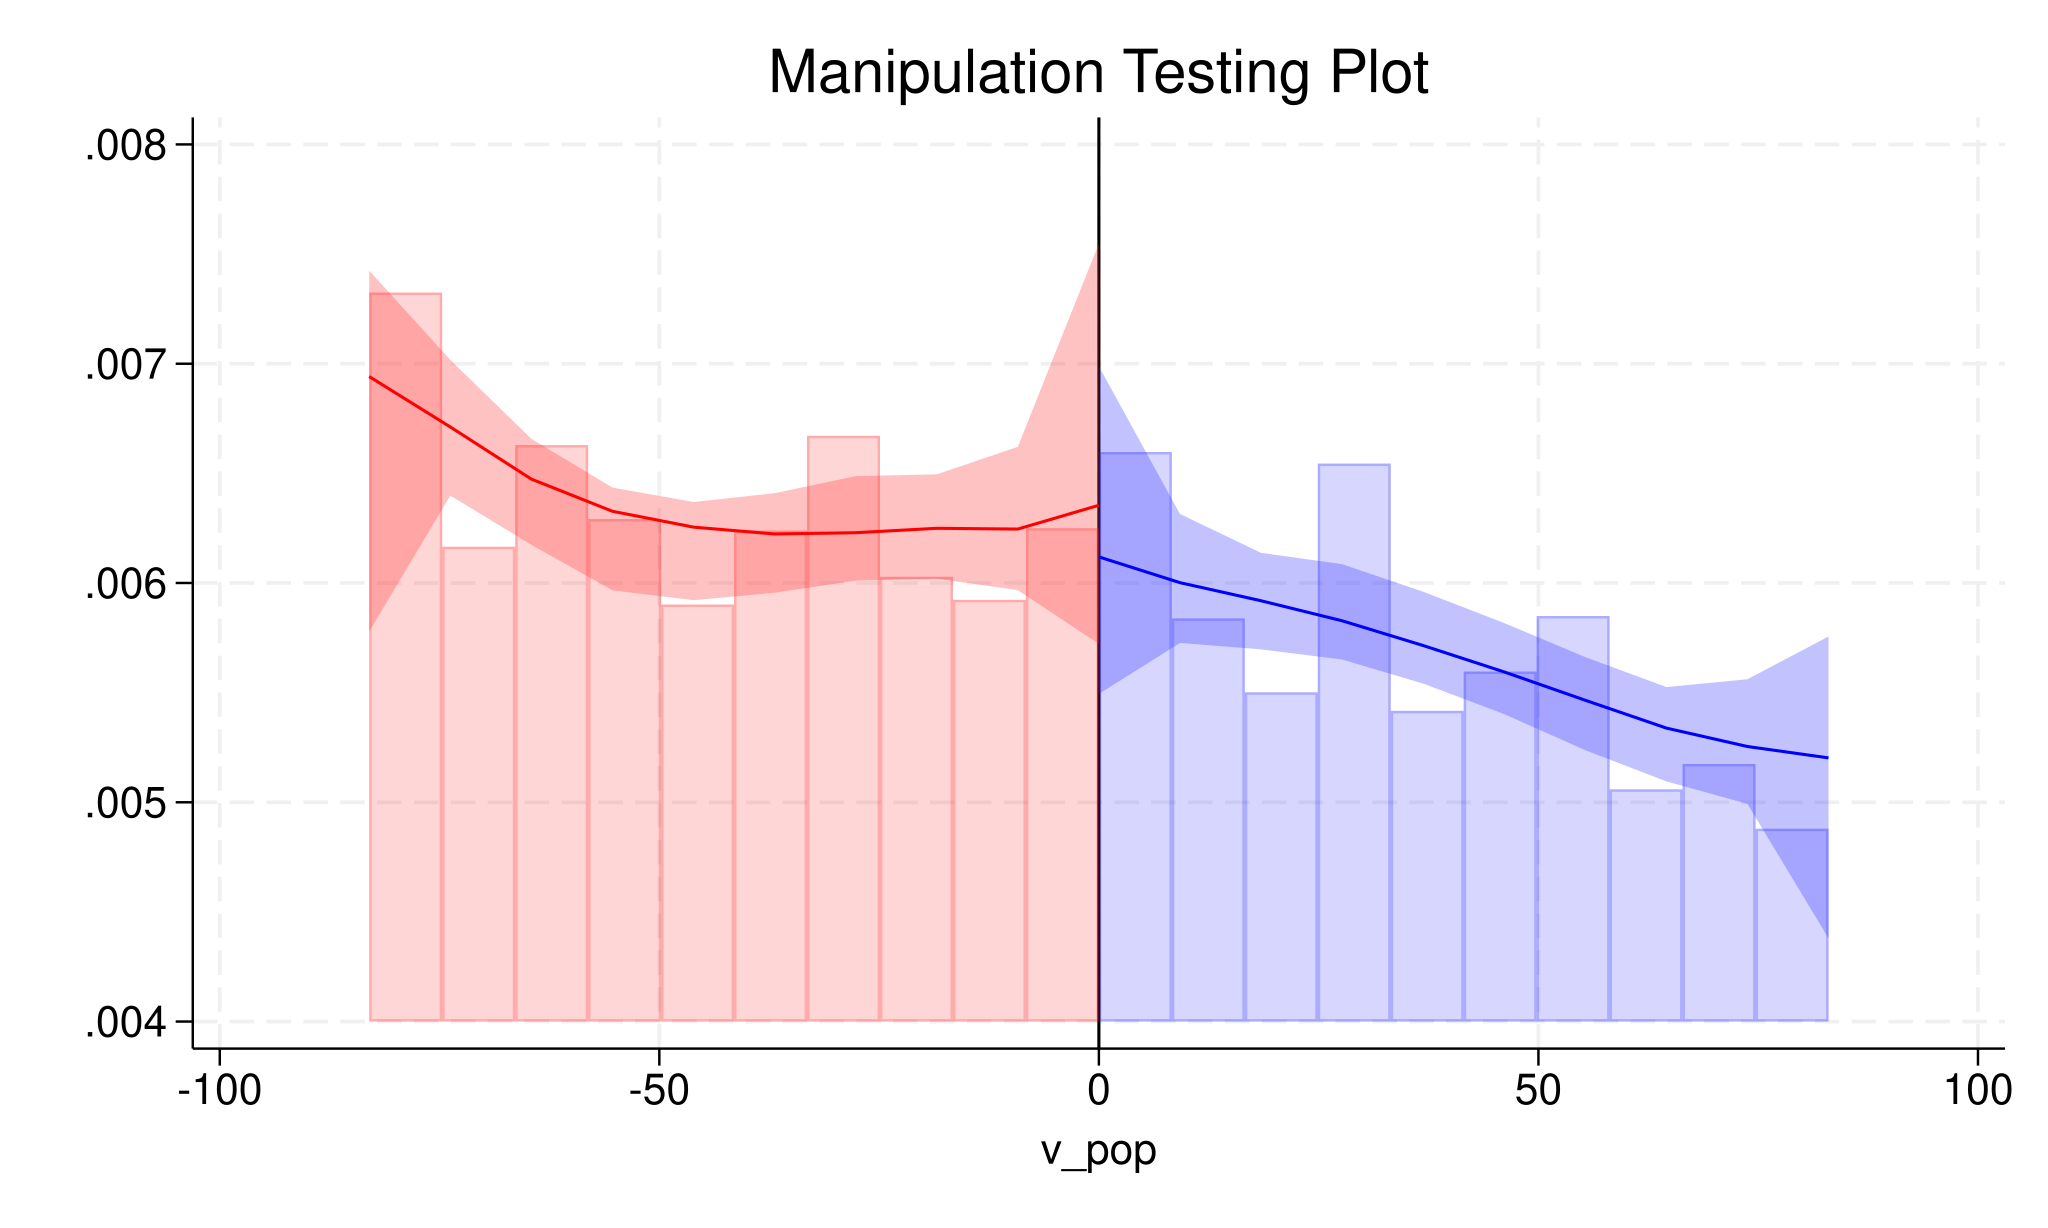

In [6]:
%%stata
// manipulation test
rddensity v_pop, plot hist_n(10)

接下来估计**第一阶段**（**first stage**）：人口门槛是否确实提高了 2012 年修路的概率。第一条是加权最小二乘（`[aw = kw]`），第二条用 `reghdfe` 加入控制变量与区县固定效应，第三条再加入二次项；最后用 `rdrobust` 给出数据驱动窗宽下、偏差校正的第一阶段估计。

In [7]:
%%stata
// first-stage
reg r2012 t l1 r1 [aw = kw], cluster(`clse')
reghdfe r2012 t l1 r1 `controls' [aw = kw], a(`fe') cluster(`clse')
reghdfe r2012 t l1 l2 r1 r2 `controls' [aw = kw], a(`fe') cluster(`clse')
rdrobust r2012 v_pop, c(0) covs(`controls')
rdrobust r2012 v_pop, c(0) p(2) covs(`controls')


. // first-stage
. reg r2012 t l1 r1 [aw = kw], cluster(`clse')
(sum of wgt is 442,872)

Linear regression                               Number of obs     =     10,911
                                                F(3, 160)         =      33.83
                                                Prob > F          =     0.0000
                                                R-squared         =     0.0504
                                                Root MSE          =     .46904

                              (Std. err. adjusted for 161 clusters in dist_id)
------------------------------------------------------------------------------
             |               Robust
       r2012 | Coefficient  std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
           t |     .19946   .0295547     6.75   0.000     .1410925    .2578275
          l1 |  -.0004947   .0003031    -1.63   0.105    -.0010934     .000104
    

把第一阶段画出来：`rdplot` 把运行变量分成若干等宽（这里取 mimicking variance）的箱，画出箱内均值与两侧的多项式拟合曲线，可以直观看到断点处修路概率的跳跃。


. // graph
. sort v_pop

. rdplot r2012 v_pop, p(1) h(`bw') kernel(tri)
Mass points detected in the running variable.

RD Plot with evenly spaced mimicking variance number of bins using polynomial r
> egression.

         Cutoff c = 0 | Left of c  Right of c        Number of obs  =      1143
> 2
----------------------+----------------------        Kernel         = Triangula
> r
        Number of obs |      6018        5414
   Eff. Number of obs |      5789        5248
  Order poly. fit (p) |         1           1
     BW poly. fit (h) |    80.000      80.000
 Number of bins scale |     1.000       1.000

Outcome: r2012. Running variable: v_pop.
---------------------------------------------
                      | Left of c  Right of c
----------------------+----------------------
        Bins selected |       133         132
   Average bin length |     0.624       0.629
    Median bin length |     0.624       0.629
----------------------+----------------------
    IMSE-optimal bins | 

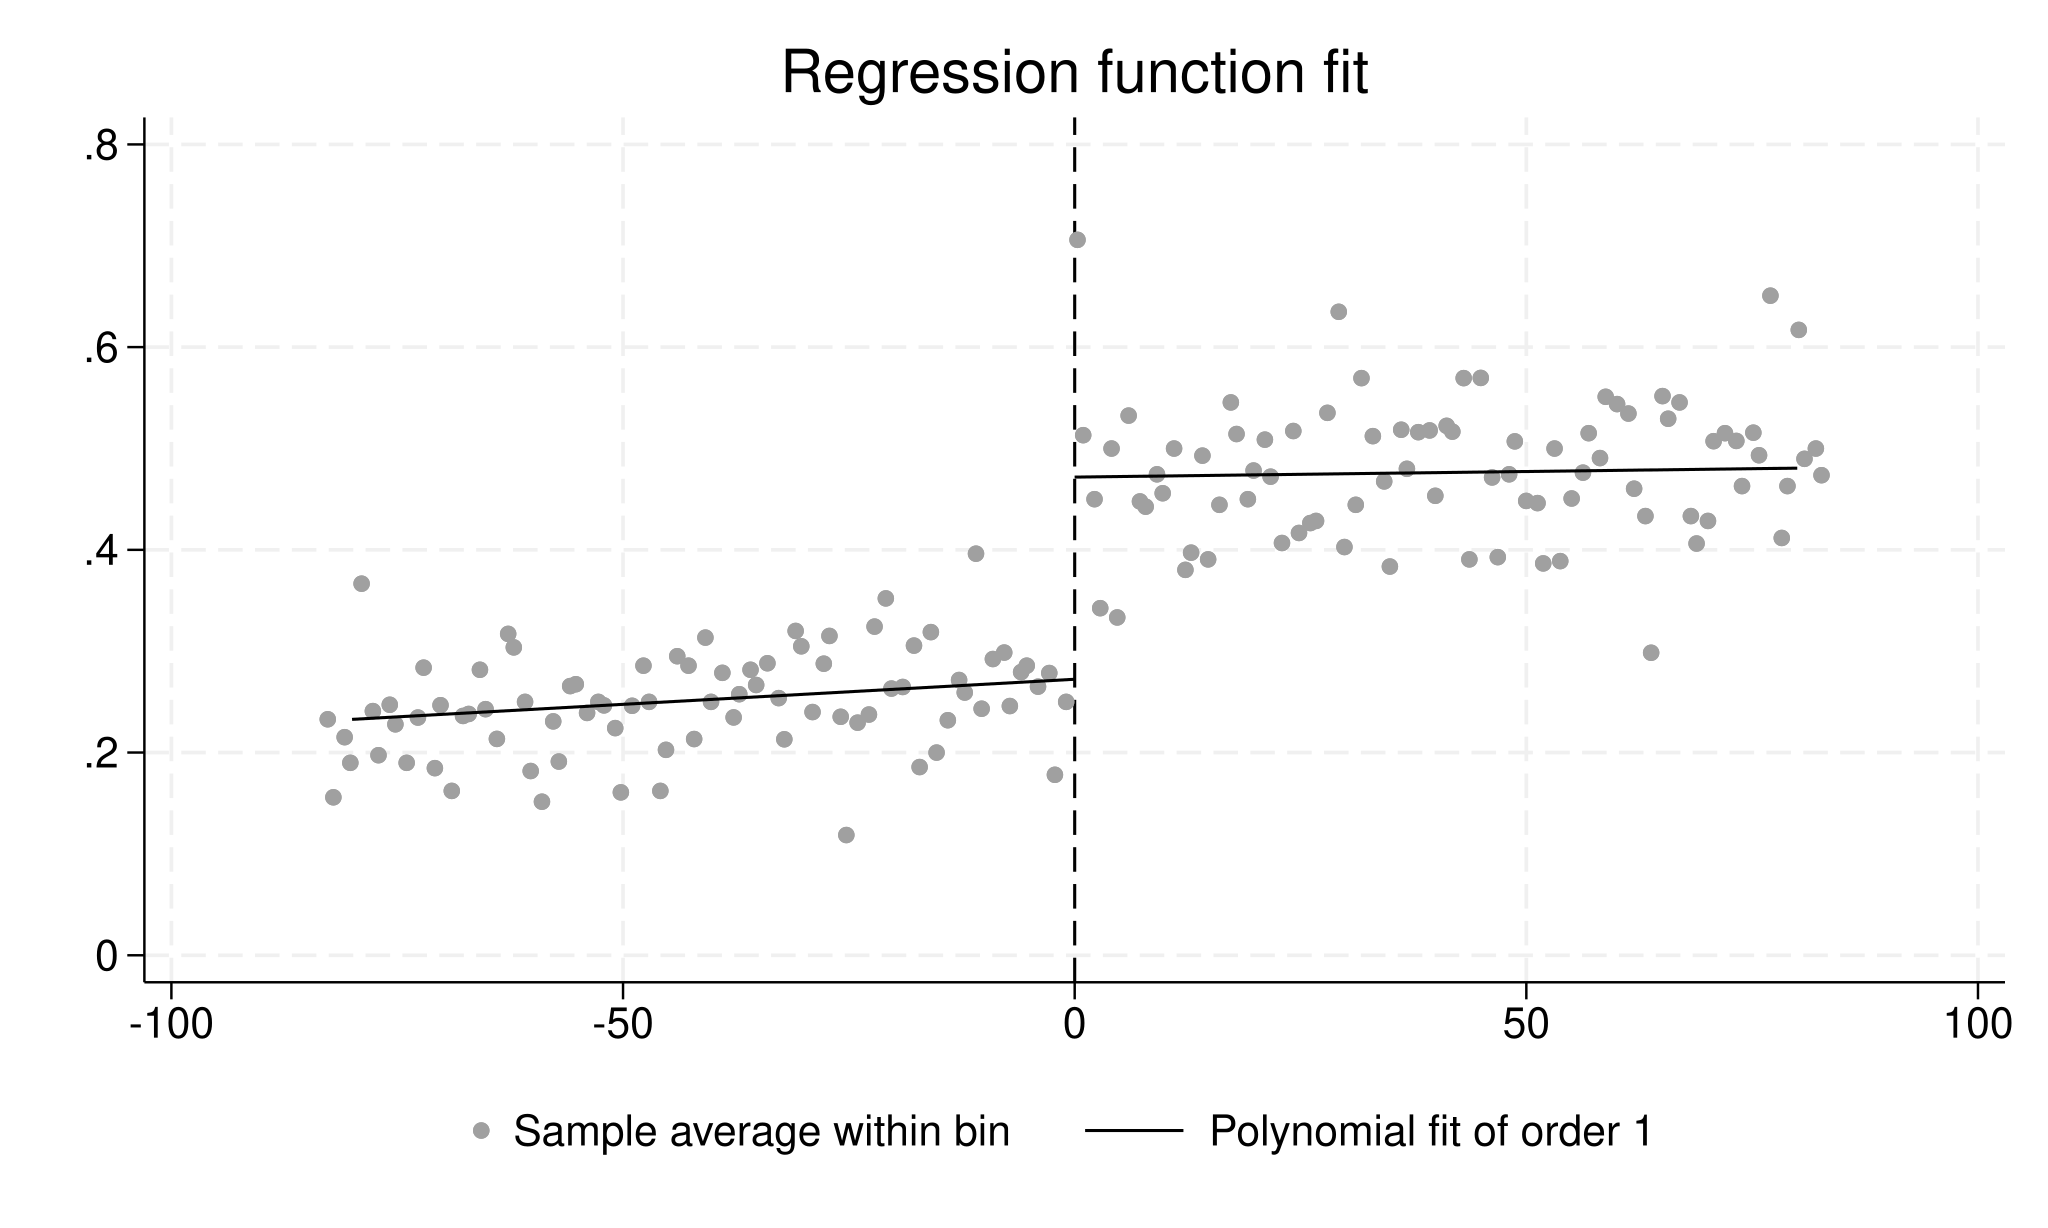

In [8]:
%%stata
// graph
sort v_pop
rdplot r2012 v_pop, p(1) h(`bw') kernel(tri)

**意向处理效应**（**intent-to-treat**，ITT）用资格 `t` 作为处理变量，估计“获得修路资格”对交通可达性指数的影响。由于并非所有获得资格的村庄都修了路，这只是 reduced form（简约式）效应，其绝对值小于实际修路的效应。

In [9]:
%%stata
// ITT
reg transport_index_andrsn t l1 r1 [aw = kw], cluster(`clse')
reghdfe transport_index_andrsn t l1 r1 `controls' [aw = kw], a(`fe') cluster(`clse')
reghdfe transport_index_andrsn t l1 l2 r1 r2 `controls' [aw = kw], a(`fe') cluster(`clse')
rdrobust transport_index_andrsn v_pop, c(0) covs(`controls')
rdrobust transport_index_andrsn v_pop, c(0) p(2) covs(`controls')


. // ITT
. reg transport_index_andrsn t l1 r1 [aw = kw], cluster(`clse')
(sum of wgt is 442,872)

Linear regression                               Number of obs     =     10,911
                                                F(3, 160)         =      17.07
                                                Prob > F          =     0.0000
                                                R-squared         =     0.0048
                                                Root MSE          =     1.0843

                              (Std. err. adjusted for 161 clusters in dist_id)
------------------------------------------------------------------------------
             |               Robust
transport_~n | Coefficient  std. err.      t    P>|t|     [95% conf. interval]
-------------+----------------------------------------------------------------
           t |   .0946668   .0439438     2.15   0.033     .0078821    .1814516
          l1 |  -.0015707   .0008018    -1.96   0.052    -.0031542    .000

同样地，我们画出结果变量在断点两侧的形态，检查是否存在明显的跳跃以及函数形式是否合理。


. // graph
. sort v_pop

. rdplot transport_index_andrsn v_pop, p(1) h(`bw') kernel(tri)
Mass points detected in the running variable.

RD Plot with evenly spaced mimicking variance number of bins using polynomial r
> egression.

         Cutoff c = 0 | Left of c  Right of c        Number of obs  =      1143
> 2
----------------------+----------------------        Kernel         = Triangula
> r
        Number of obs |      6018        5414
   Eff. Number of obs |      5789        5248
  Order poly. fit (p) |         1           1
     BW poly. fit (h) |    80.000      80.000
 Number of bins scale |     1.000       1.000

Outcome: transport_index_andrsn. Running variable: v_pop.
---------------------------------------------
                      | Left of c  Right of c
----------------------+----------------------
        Bins selected |       133         131
   Average bin length |     0.624       0.634
    Median bin length |     0.624       0.634
----------------------+-------------

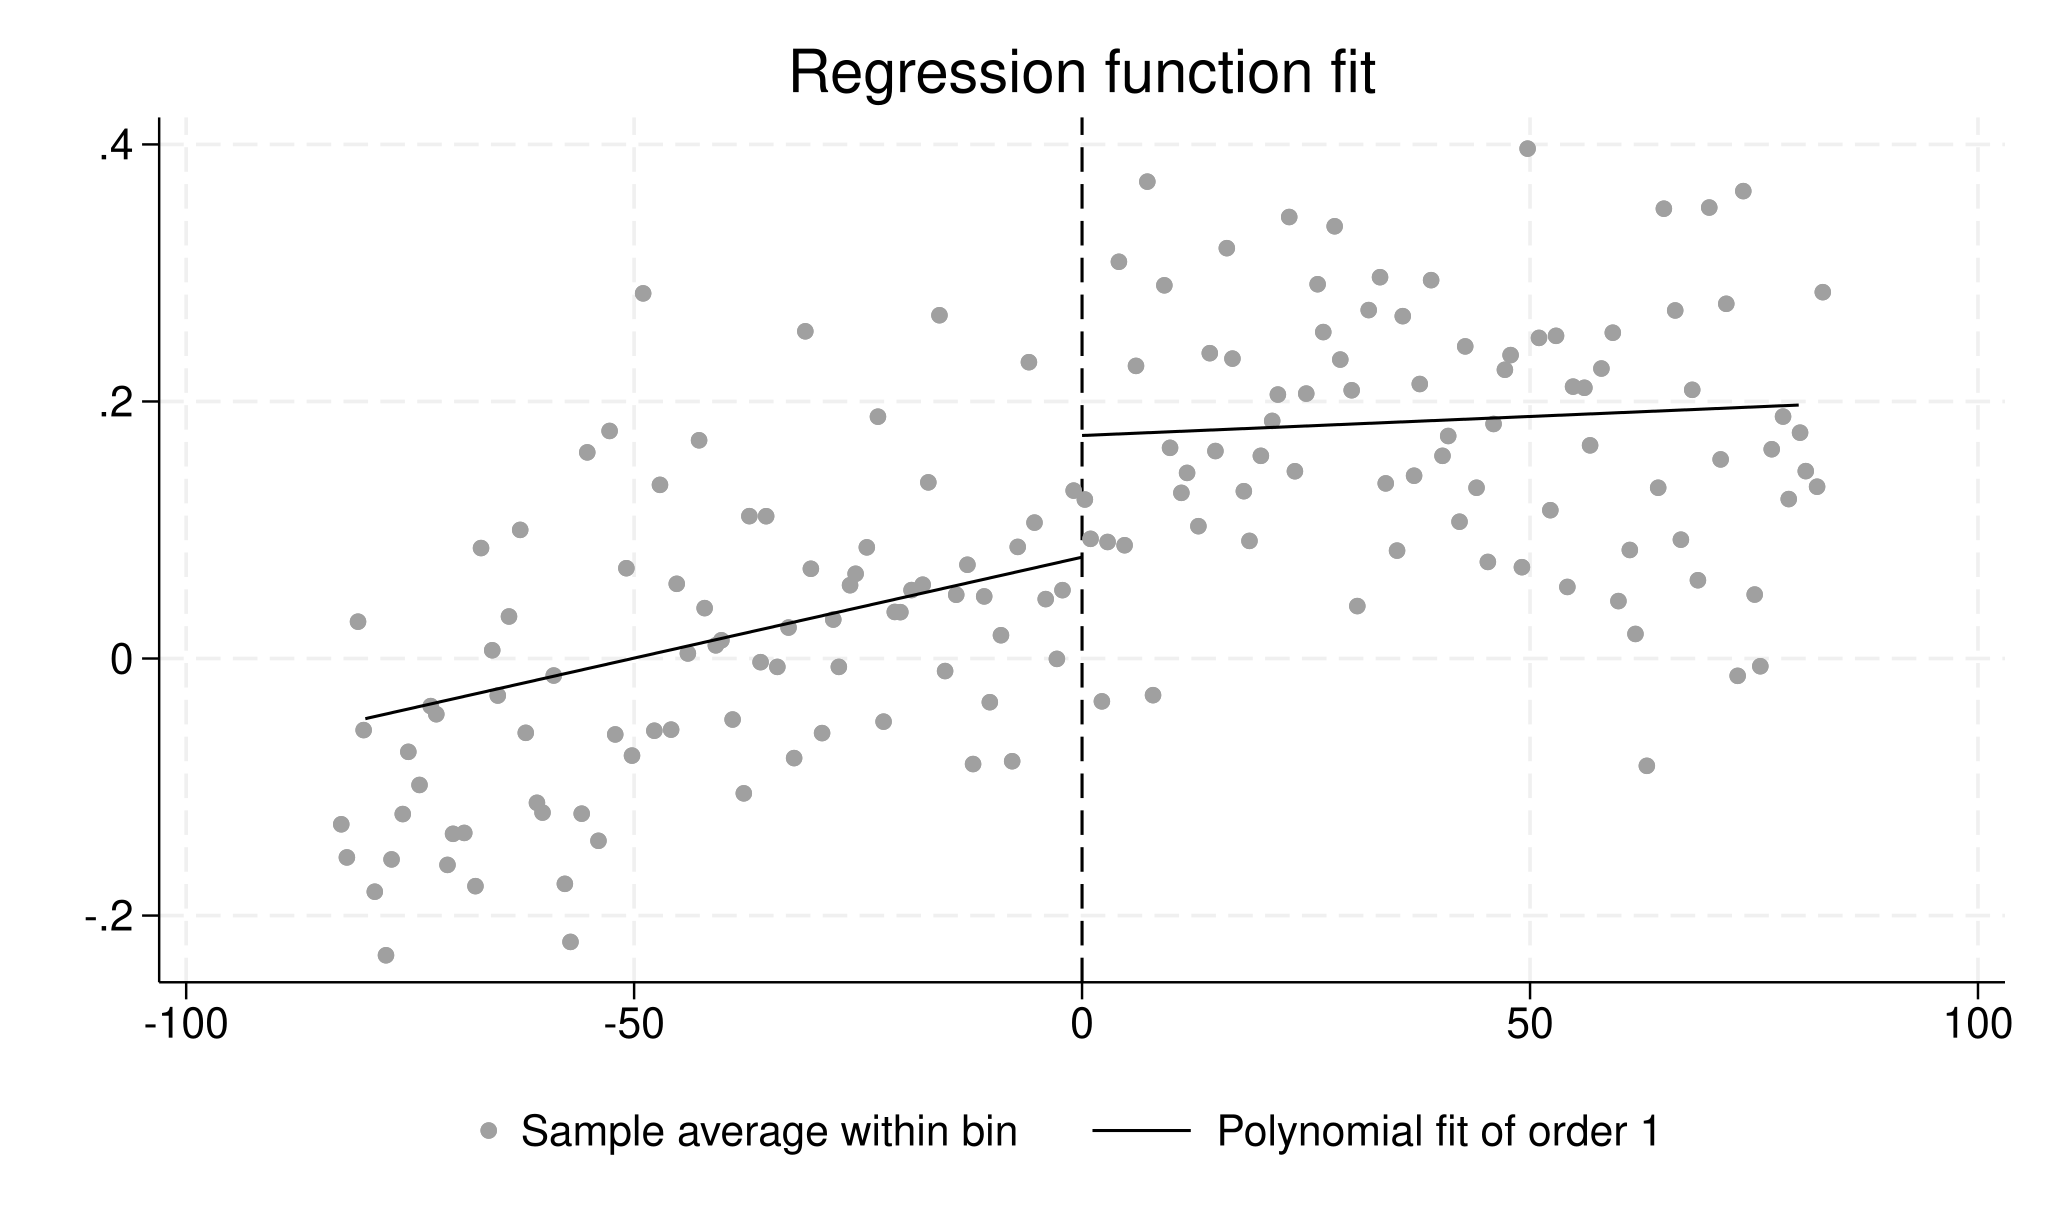

In [10]:
%%stata
// graph
sort v_pop
rdplot transport_index_andrsn v_pop, p(1) h(`bw') kernel(tri)

最后把二者结合起来：模糊断点回归等价于以 `t` 为工具变量、以 `r2012` 为内生处理变量的两阶段最小二乘，识别出的是断点附近“依从者”（**compliers**）的**局部平均处理效应**（**LATE**）。先做加权 2SLS，再用 `ivreghdfe` 控制固定效应与控制变量；`rdrobust ... fuzzy(r2012)` 则在数据驱动窗宽下给出偏差校正的模糊断点估计。注意 `rdplot` 会残留不完整的 `e()` 结果，因此先用 `ereturn clear` 清空，否则 `ivregress` 会报 `r(301)`。

In [11]:
%%stata
// Fuzzy or IV
// 注意：rdplot 会残留不完整的 e() 结果，需先清除，否则 ivregress 会报 r(301)
ereturn clear
ivregress 2sls transport_index_andrsn (r2012=t) l1 r1 [aw = kw], cluster(`clse')
ivreghdfe transport_index_andrsn (r2012=t) l1 r1 `controls' [aw = kw], a(`fe') cluster(`clse')
ivreghdfe transport_index_andrsn (r2012=t) l1 l2 r1 r2 `controls' [aw = kw], a(`fe') cluster(`clse')
rdrobust transport_index_andrsn v_pop, c(0) covs(`controls') fuzzy(r2012)
rdrobust transport_index_andrsn v_pop, c(0) p(2) covs(`controls') fuzzy(r2012)


. // Fuzzy or IV
. // 注意：rdplot 会残留不完整的 e() 结果，需先清除，否则 ivregress 会报 r(301)
. ereturn clear

. ivregress 2sls transport_index_andrsn (r2012=t) l1 r1 [aw = kw], cluster(`cls
> e')
(sum of wgt is   4.4287e+05)

Instrumental-variables 2SLS regression            Number of obs   =     10,911
                                                  Wald chi2(3)    =      51.14
                                                  Prob > chi2     =     0.0000
                                                  R-squared       =          .
                                                  Root MSE        =     1.0868

                              (Std. err. adjusted for 161 clusters in dist_id)
------------------------------------------------------------------------------
             |               Robust
transport_~n | Coefficient  std. err.      z    P>|z|     [95% conf. interval]
-------------+----------------------------------------------------------------
       r2012 |   .4746155   .2171136     2.